## Mini Projet:Analyse des Données d'une série temporelle sur les passagers aériens.

### Étape 1 : Chargement des données

In [ ]:
# 1 importez les bilbliothèques:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# chager le jeu de données
df=pd.read_csv(r"C:\Users\agcharrabiaa\OneDrive\log\Documents\S5-S6\Serie_Temporelle\datasets\AirPassengers.csv",index_col="Month",parse_dates=True)
df.head(10)

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
1949-06-01,135
1949-07-01,148
1949-08-01,148
1949-09-01,136


### Étape 2 :Visualisation des données

<Figure size 864x432 with 0 Axes>

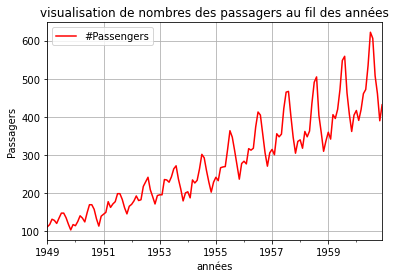

In [ ]:
plt.figure(figsize=(12, 6))
df.plot(title="visualisation de nombres des passagers au fil des années", xlabel="années", ylabel="Passagers", color="red")
plt.grid(True)
plt.show()

Interpritation :

Le graphique représente l'évolution du nombre de passagers au fil des années, de 1949 à 1959.
Tendances Principales :
Croissance globale: On observe une tendance générale à la hausse du nombre de passagers sur la période considérée. Cela suggère une croissance continue du secteur des transports aériens pendant ces années.
Fluctuations saisonnières: Les données montrent des fluctuations régulières du nombre de passagers d'une année à l'autre. Ces variations saisonnières pourraient être liées à des facteurs tels que les vacances, les fêtes ou les événements économiques.

### Étape 3 : Les opérations sur la série temporelle

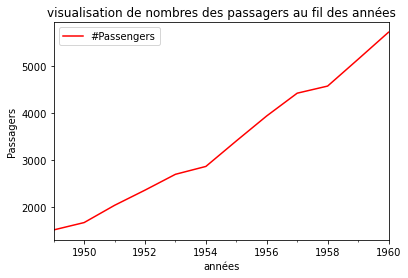

In [ ]:
# 3 les operations sur les séries temporelles :
data_res=df.resample("Y").sum()
data_res.plot(title="visualisation de nombres des passagers au fil des années", xlabel="années", ylabel="Passagers", color="red")
plt.show()

Interpritation :
Cette ligne regroupe les données dans le DataFrame df par année (grâce à "Y", qui correspond à une fréquence annuelle) et calcule la somme des valeurs pour chaque année.
La méthode .resample("Y") regroupe les données par années..sum() additionne les valeurs de chaque groupe.
Le DataFrame data_res contient une version agrégée de df, où chaque ligne représente une année, et la valeur correspondante est la somme des données pour cette année.

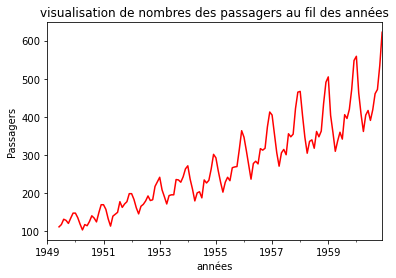

In [ ]:
data_backward=df['#Passengers'].shift(5)
data_backward.plot(title="visualisation de nombres des passagers au fil des années", xlabel="années", ylabel="Passagers", color="red")
plt.show()


Interpritation :
Décalage des données:
data_backward=df['#Passengers'].shift(5) : Cette ligne décale la série temporelle des passagers de 5 périodes vers le passé. En d'autres termes, la valeur d'une année donnée sera remplacée par la valeur qui était présente 5 années auparavant.

### Étape 4 : Vérification de la stationnarité de cette série temporelle

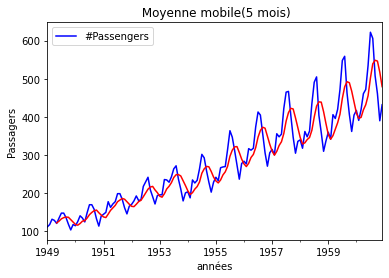

In [ ]:
roll_main=df['#Passengers'].rolling(window=5).mean()
df.plot(title=" original", xlabel="années", ylabel="Passagers", color="blue")
roll_main.plot(title=" Moyenne mobile(5 mois)", xlabel="années", ylabel="Passagers", color="red")
plt.show()

In [ ]:
# Séléction des dates où le nombre de passagers est inférieur à 120.
nbr_passagers=df[df['#Passengers']<120]
nbr_passagers


,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-10-01,119
1949-11-01,104
1949-12-01,118
1950-01-01,115
1950-11-01,114


### Étape 4 : Vérification de la stationnarité de cette série temporelle

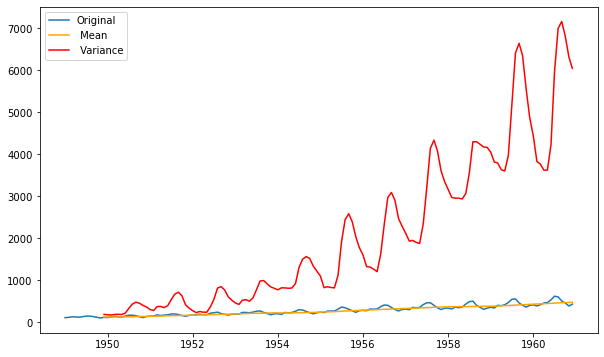

In [ ]:
# Vérification de la stationnarité de cette série temporelle
#Plot rolling mean and variance
roll_mean = df['#Passengers'].rolling(window=12).mean()
roll_var = df['#Passengers'].rolling(window=12).var()

plt.figure(figsize=(10, 6))
plt.plot(df['#Passengers'], label='Original')
plt.plot(roll_mean, label=' Mean', color='orange')
plt.plot(roll_var, label=' Variance', color='red')
plt.legend()
plt.show()

Interpritation:

En observant le graphique, on peut faire les observations suivantes:
Tendance: La moyenne mobile présente une tendance à la hausse, ce qui suggère que le nombre de passagers augmente en moyenne au fil du temps. Cela indique une non-stationnarité en moyenne.
Variance: La variance mobile semble également augmenter avec le temps, ce qui indique une non-stationnarité en variance.

In [ ]:
# test ADF verifier la stationarité
from statsmodels.tsa.stattools import adfuller
adf_test = adfuller(df['#Passengers'].dropna())
print("statistique ADF:", adf_test[0])
print("p-value:", adf_test[1])

ADF Statistic: 0.8153688792060463
p-value: 0.991880243437641


Interpritation:

Les résultats du test ADF sont les suivants :
Statistique ADF: 0.8153688792060463
p-valeur: 0.991880243437641
Interprétation de la p-valeur:

Règle générale: Si la p-valeur est inférieure au seuil de signification (typiquement 5%), on rejette l'hypothèse nulle et on conclut que la série est stationnaire.
Dans notre cas: La p-valeur est très élevée (proche de 1), ce qui signifie que nous ne pouvons pas rejeter l'hypothèse nulle.

### Étape 5 : Rendre le série temporelle

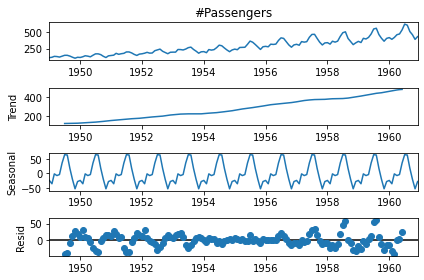

In [ ]:
# Étape 5 : Rendre le série temporelle

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Differenciation
data_diff = df['#Passengers'].diff().dropna()
# Log transformation
data_log = np.log(df['#Passengers'])
# Decomposition
decomposition = seasonal_decompose(df['#Passengers'], model='additive')
decomposition.plot()
plt.show()

Interpritation

En se basant sur ces graphes, on peut tirer les conclusions suivantes :
Tendance à la hausse: Le nombre de passagers a globalement augmenté au cours de la période considérée.
Saisonnalité: Il existe une composante saisonnière dans les données, ce qui suggère que la demande varie de manière régulière au cours de l'année.
Résidu: La composante résiduelle semble relativement aléatoire, mais il pourrait y avoir d'autres facteurs non capturés par la tendance et la saisonnalité qui influencent le nombre de passagers.

### Étape 6 : Autocorrélation

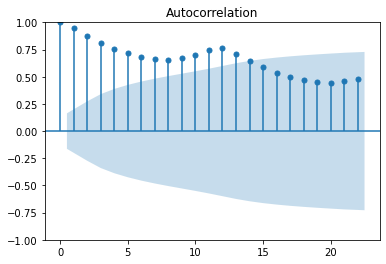

C:\Users\agcharrabiaa\anaconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


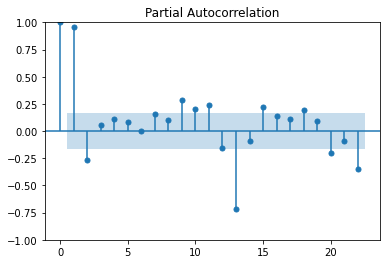

In [ ]:
# Step 6: Autocorrelation Analysis
# Plot ACF and PACF
plot_acf(df['#Passengers'])
plt.show()

plot_pacf(df['#Passengers'])
plt.show()


Interpritation :
Le graphique ACF montre une décroissance lente et régulière des coefficients d'autocorrélation au fur et à mesure que le décalage augmente. Les barres bleues représentent les valeurs des coefficients d'autocorrélation, et les zones ombrées représentent les intervalles de confiance.
pour le PACF on observe:
 Le coefficient d'autocorrélation partielle est significativement différent de zéro au premier décalage. Cela suggère une forte corrélation directe entre une observation et l'observation précédente.
Quelques autres pics significatifs: On observe d'autres pics significatifs à des décalages plus élevés, mais leur amplitude est généralement inférieure à celle du premier pic.
Décroissance rapide: Après les premiers pics, les coefficients d'autocorrélation partielle décroissent rapidement vers zéro, ce qui indique que l'effet des observations passées diminue rapidement.

### Étape 7 : Modélisation

In [ ]:
#Étape 7 : Modélisation
# Fit ARIMA model
model = ARIMA(df['#Passengers'], order=(1, 1, 1))
model_fit = model.fit()
# description du model
print(model_fit.summary())

C:\Users\agcharrabiaa\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\agcharrabiaa\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\agcharrabiaa\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:            #Passengers   No. Observations:                  144
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -694.341
Date:                Thu, 12 Dec 2024   AIC                           1394.683
Time:                        20:04:31   BIC                           1403.571
Sample:                    01-01-1949   HQIC                          1398.294
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4742      0.123     -3.847      0.000      -0.716      -0.233
ma.L1          0.8635      0.078     11.051      0.000       0.710       1.017
sigma2       961.9270    107.433      8.954      0.0

### Étape 8 : Prévisions

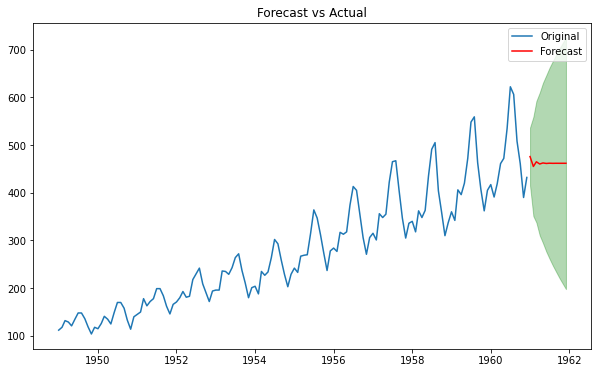

In [ ]:
#Étape 8 : Prévisions
# previsions 12 mois suivantes
forecast = model_fit.get_forecast(steps=12)
forecast_index = pd.date_range(df.index[-1], periods=12, freq='M')
plt.figure(figsize=(10, 6))
plt.plot(df['#Passengers'], label='Original')
plt.plot(forecast_index, forecast.predicted_mean, label='prévision', color='red')
plt.fill_between( forecast_index,forecast.conf_int()['lower #Passengers'],forecast.conf_int()['upper #Passengers'], color='green', alpha=0.3)
plt.title("Forecast vs Actual")
plt.legend()
plt.show()


 Interpritation :

 La ligne bleue montre les données historiques du nombre de passagers au fil du temps. On observe une tendance à la hausse, indiquant une augmentation régulière du nombre de passagers au fil des années.
 La ligne rouge représente les prévisions du nombre de passagers pour les 12 mois à venir. Elle prolonge la tendance observée dans les données historiques.
 La zone verte ombrée illustre l’intervalle de confiance des prévisions. Cet intervalle indique l’incertitude des prédictions. Plus il est large, plus l’incertitude est importante.


2. Quels sont les principaux facteurs influençant le nombre des passagers ?
Facteurs économiques: Le niveau de vie, le taux de chômage, les revenus disponibles, les prix des carburants influencent directement la capacité des individus à voyager.
Facteurs démographiques: La taille de la population, la répartition par âge, la densité de population dans les zones desservies impactent la demande.
Facteurs saisonniers: Les vacances scolaires, les fêtes religieuses, les événements saisonniers (comme les festivals) entraînent des variations saisonnières de la demande.
Facteurs liés aux événements: Des événements particuliers (concerts, conférences, manifestations sportives) peuvent générer des pics de fréquentation.